Starting Data Engineering Pipeline

Loading ULB dataset...

Dataset: ULB Credit Card Fraud

Dataset Size:
(284807, 31)

Number of Features:
31

Data Types:
float64    30
int64       1
Name: count, dtype: int64

Missing Values:
0

Duplicates:
1081

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Running EDA...


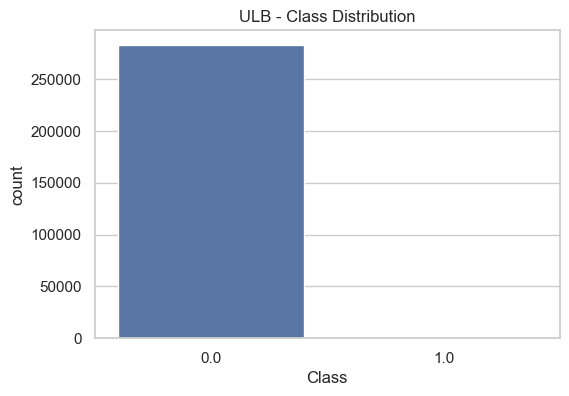

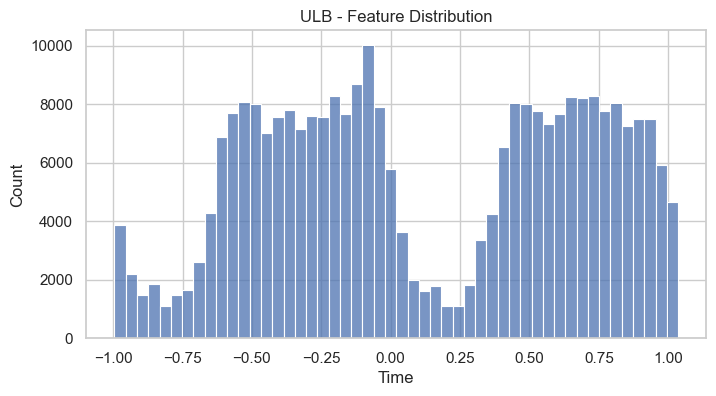

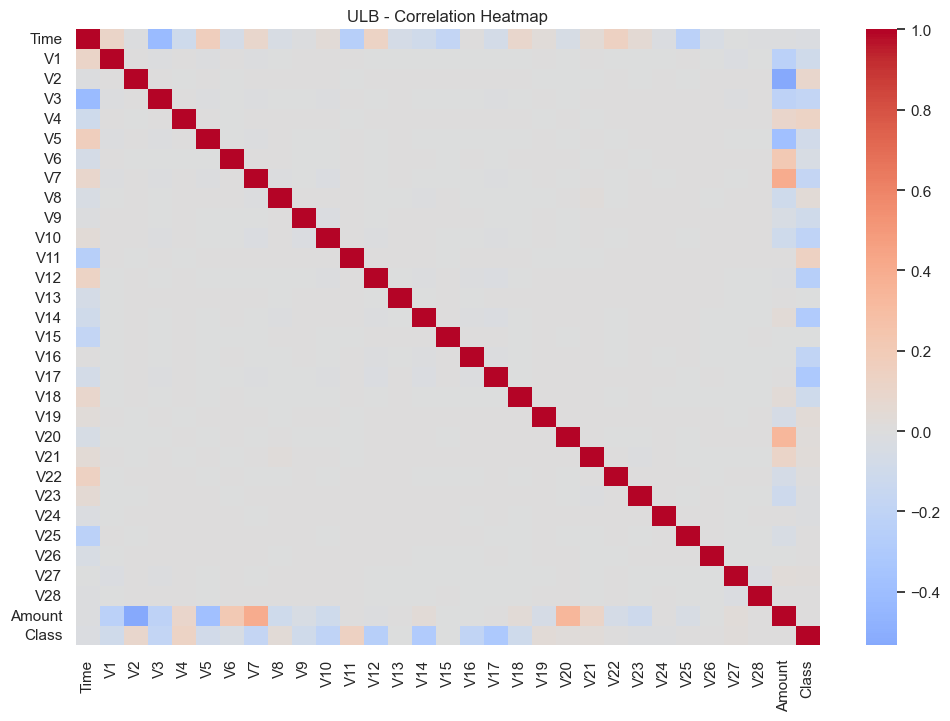


Top Features Correlated with Fraud:
Class     1.000000
V11       0.149067
V4        0.129326
V2        0.084624
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
V28       0.009682
Amount    0.005777
V22       0.004887
V26       0.004265
V25       0.003202
V15      -0.003300
V13      -0.003897
V23      -0.006333
V24      -0.007210
Time     -0.012359
V6       -0.043915
V5       -0.087812
V9       -0.094021
V1       -0.094486
V18      -0.105340
V7       -0.172347
V3       -0.182322
V16      -0.187186
V10      -0.206971
V12      -0.250711
V14      -0.293375
V17      -0.313498
Name: Class, dtype: float64

Top 10 Features:
V11       0.149067
V4        0.129326
V2        0.084624
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
V28       0.009682
Amount    0.005777
Name: Class, dtype: float64


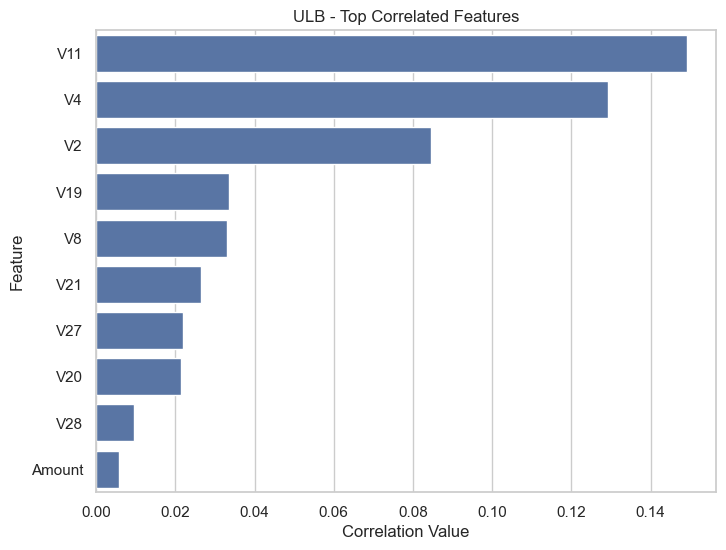

ULB dataset processed

Loading IEEE dataset...

Dataset: IEEE Fraud Dataset

Dataset Size:
(590540, 434)

Number of Features:
434

Data Types:
float64    399
str         31
int64        4
Name: count, dtype: int64

Missing Values:
115523073

Duplicates:
0

Class Distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Running EDA...


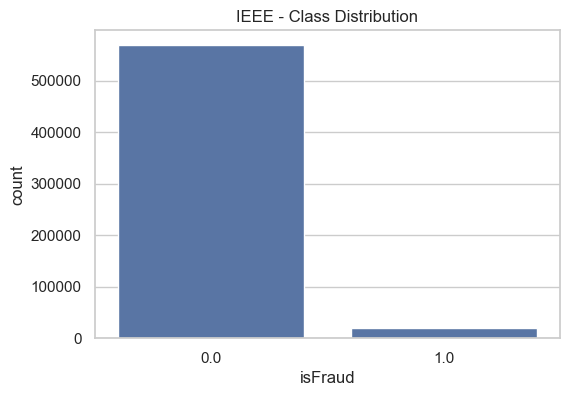

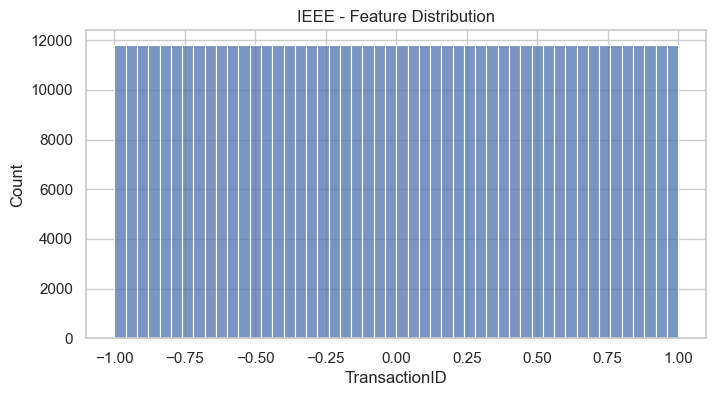

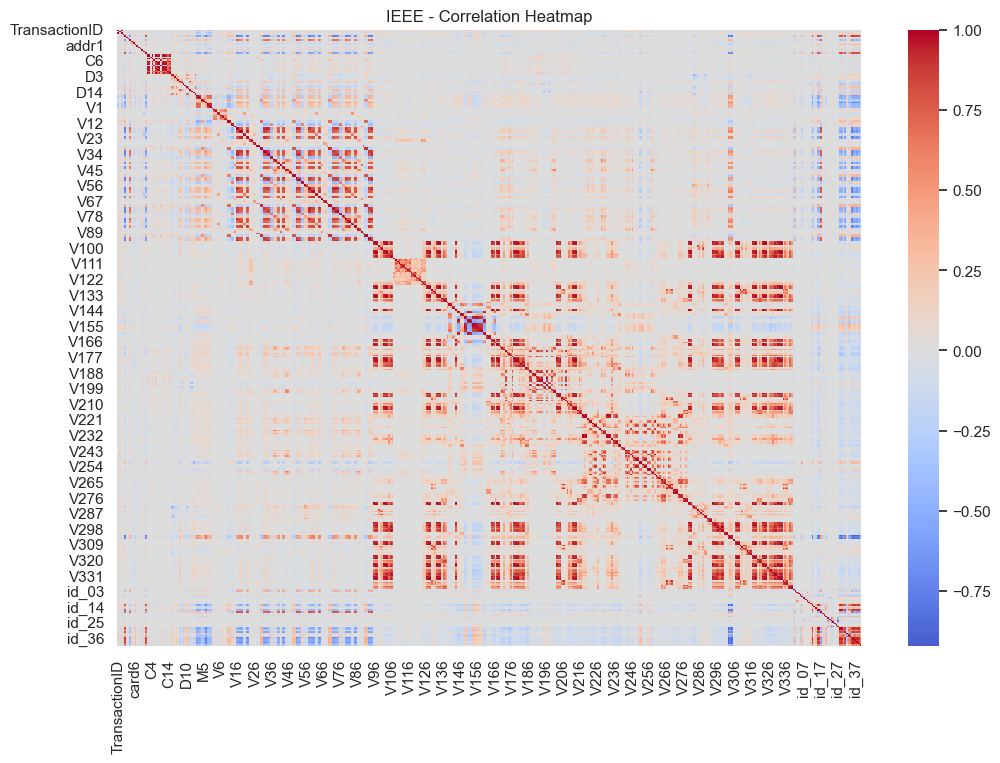


Top Features Correlated with Fraud:
isFraud      1.000000
V257         0.280214
V246         0.268090
V244         0.265712
V242         0.263476
               ...   
id_38       -0.145124
id_28       -0.150640
id_29       -0.151940
ProductCD   -0.156556
id_35       -0.164236
Name: isFraud, Length: 434, dtype: float64

Top 10 Features:
V257    0.280214
V246    0.268090
V244    0.265712
V242    0.263476
V201    0.246462
V200    0.238290
V45     0.235436
V189    0.225829
V86     0.222343
V87     0.221568
Name: isFraud, dtype: float64


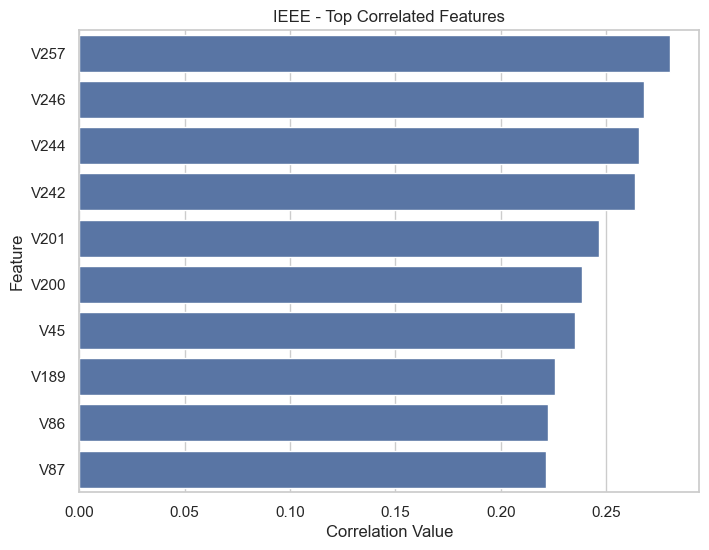

IEEE dataset processed

Loading PaySim dataset...

Dataset: PaySim Dataset

Dataset Size:
(6362620, 11)

Number of Features:
11

Data Types:
float64    5
int64      3
str        3
Name: count, dtype: int64

Missing Values:
0

Duplicates:
0

Class Distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Running EDA...


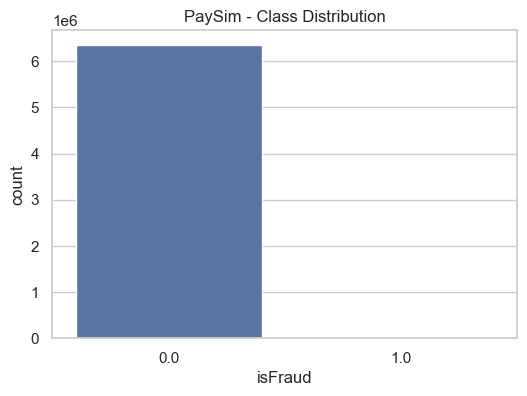

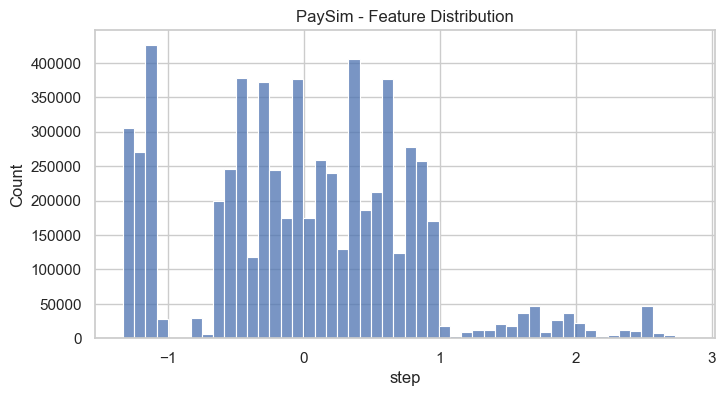

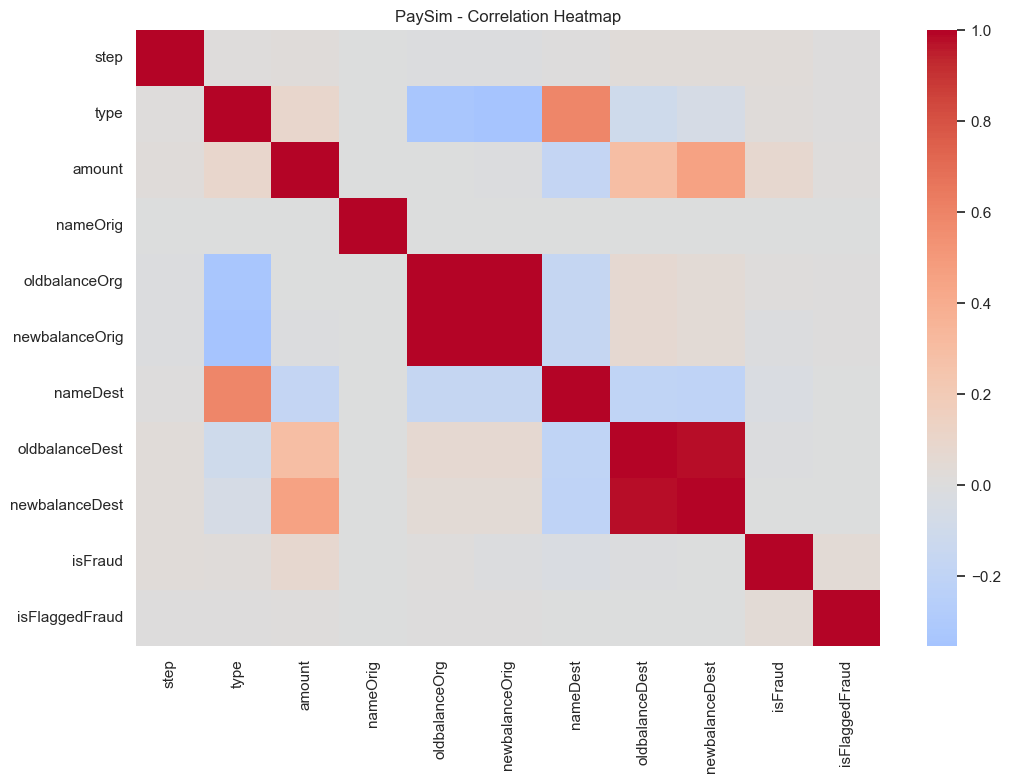


Top Features Correlated with Fraud:
isFraud           1.000000
amount            0.076688
isFlaggedFraud    0.044109
step              0.031578
type              0.020833
oldbalanceOrg     0.010154
newbalanceDest    0.000535
nameOrig         -0.000464
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
nameDest         -0.021963
Name: isFraud, dtype: float64

Top 10 Features:
amount            0.076688
isFlaggedFraud    0.044109
step              0.031578
type              0.020833
oldbalanceOrg     0.010154
newbalanceDest    0.000535
nameOrig         -0.000464
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
nameDest         -0.021963
Name: isFraud, dtype: float64


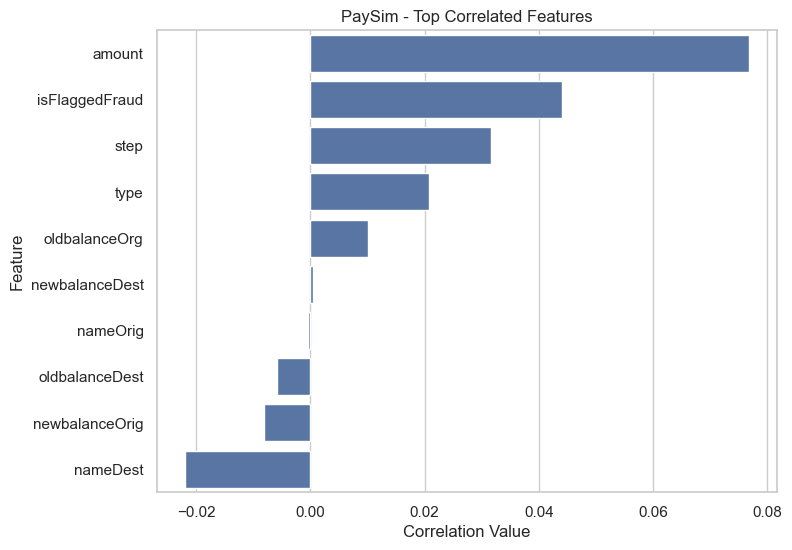

PaySim dataset processed

All datasets processed successfully


In [1]:
# ==========================================================
# DATA ENGINEERING PIPELINE - FRAUD DETECTION
# ==========================================================

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler, LabelEncoder
import os

# Create folder to store charts
os.makedirs("charts", exist_ok=True)

print("Starting Data Engineering Pipeline")

# ==========================================================
# DATASET ANALYSIS
# ==========================================================

def analyze_dataset(df, name, label):

    print("\n================================")
    print(f"Dataset: {name}")
    print("================================")

    print("\nDataset Size:")
    print(df.shape)

    print("\nNumber of Features:")
    print(len(df.columns))

    print("\nData Types:")
    print(df.dtypes.value_counts())

    print("\nMissing Values:")
    print(df.isnull().sum().sum())

    print("\nDuplicates:")
    print(df.duplicated().sum())

    if label in df.columns:
        print("\nClass Distribution:")
        print(df[label].value_counts())


# ==========================================================
# DATA PROCESSING
# ==========================================================

def process_dataset(df):

    # Remove duplicates
    df = df.drop_duplicates()

    # Handle missing values
    df = df.fillna(df.median(numeric_only=True))

    # Encode categorical variables
    for column in df.select_dtypes(include=['object','string']).columns:
        encoder = LabelEncoder()
        df[column] = encoder.fit_transform(df[column].astype(str))

    # Feature scaling
    scaler = RobustScaler()
    numeric_cols = df.select_dtypes(include=['int64','float64']).columns
    df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

    return df


# ==========================================================
# EDA VISUALIZATION
# ==========================================================

def run_eda(df, label, dataset_name):

    print("\nRunning EDA...")

    sns.set(style="whitegrid")

    # Class Distribution
    if label in df.columns:
        plt.figure(figsize=(6,4))
        sns.countplot(x=label, data=df)
        plt.title(f"{dataset_name} - Class Distribution")
        plt.savefig(f"charts/{dataset_name}_class_distribution.png")
        plt.show()

    # Histogram
    numeric_cols = df.select_dtypes(include=['float64','int64']).columns
    if len(numeric_cols) > 0:
        plt.figure(figsize=(8,4))
        sns.histplot(df[numeric_cols[0]], bins=50)
        plt.title(f"{dataset_name} - Feature Distribution")
        plt.savefig(f"charts/{dataset_name}_feature_distribution.png")
        plt.show()

    # Correlation Heatmap
    plt.figure(figsize=(12,8))
    corr_matrix = df.corr()
    sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
    plt.title(f"{dataset_name} - Correlation Heatmap")
    plt.savefig(f"charts/{dataset_name}_correlation_heatmap.png")
    plt.show()


# ==========================================================
# FEATURE IMPORTANCE ANALYSIS
# ==========================================================

def feature_analysis(df, label, dataset_name):

    if label not in df.columns:
        return

    print("\nTop Features Correlated with Fraud:")

    corr_with_class = df.corr()[label].sort_values(ascending=False)
    print(corr_with_class)

    top_features = corr_with_class.drop(label).head(10)

    print("\nTop 10 Features:")
    print(top_features)

    plt.figure(figsize=(8,6))
    sns.barplot(x=top_features.values, y=top_features.index)
    plt.title(f"{dataset_name} - Top Correlated Features")
    plt.xlabel("Correlation Value")
    plt.ylabel("Feature")
    plt.savefig(f"charts/{dataset_name}_top_features.png")
    plt.show()


# ==========================================================
# 1. ULB CREDIT CARD FRAUD DATASET
# ==========================================================

print("\nLoading ULB dataset...")

ulb = pd.read_csv("creditcard.csv")

analyze_dataset(ulb, "ULB Credit Card Fraud", "Class")

ulb = process_dataset(ulb)

run_eda(ulb, "Class", "ULB")

feature_analysis(ulb, "Class", "ULB")

ulb.to_csv("processed_ulb_dataset.csv", index=False)

print("ULB dataset processed")


# ==========================================================
# 2. IEEE FRAUD DETECTION DATASET
# ==========================================================

print("\nLoading IEEE dataset...")

transaction = pd.read_csv("train_transaction.csv")
identity = pd.read_csv("train_identity.csv")

ieee = pd.merge(transaction, identity, on="TransactionID", how="left")

analyze_dataset(ieee, "IEEE Fraud Dataset", "isFraud")

ieee = process_dataset(ieee)

run_eda(ieee, "isFraud", "IEEE")

feature_analysis(ieee, "isFraud", "IEEE")

ieee.to_csv("processed_ieee_dataset.csv", index=False)

print("IEEE dataset processed")


# ==========================================================
# 3. PAYSIM FRAUD DATASET
# ==========================================================

print("\nLoading PaySim dataset...")

paysim = pd.read_csv("PS_20174392719_1491204439457_log.csv")

analyze_dataset(paysim, "PaySim Dataset", "isFraud")

paysim = process_dataset(paysim)

run_eda(paysim, "isFraud", "PaySim")

feature_analysis(paysim, "isFraud", "PaySim")

paysim.to_csv("processed_paysim_dataset.csv", index=False)

print("PaySim dataset processed")


# ==========================================================
# PIPELINE COMPLETE
# ==========================================================

print("\nAll datasets processed successfully")